In [131]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [132]:
from sklearn.preprocessing import LabelEncoder

**Feature Engineering**

In [133]:
df=pd.read_csv("Ecommerce.csv")

In [134]:
df.head(3)

,CID,TID,Gender,Age Group,Purchase Date,Product Category,Discount Availed,Discount Name,Discount Amount (INR),Gross Amount,Net Amount,Purchase Method,Location
0,943146,5876328741,Female,25-45,30/08/2023 20:27:08,Electronics,Yes,FESTIVE50,64.30,725.304000,661.004000,Credit Card,Ahmedabad
1,180079,1018503182,Male,25-45,23/02/2024 09:33:46,Electronics,Yes,SEASONALOFFER21,175.19,4638.991875,4463.801875,Credit Card,Bangalore
2,337580,3814082218,Other,60 and above,06/03/2022 09:09:50,Clothing,Yes,SEASONALOFFER21,211.54,1986.372575,1774.832575,Credit Card,Delhi


In [135]:
df.isna().sum()/len(df)

,0
CID,0.000000
TID,0.000000
Gender,0.000000
Age Group,0.000000
Purchase Date,0.000000
Product Category,0.000000
Discount Availed,0.000000
Discount Name,0.501545
Discount Amount (INR),0.000000
Gross Amount,0.000000


In [136]:
df["Discount Name"]=df["Discount Name"].fillna("NEWYEARS")

In [137]:
df.dropna(inplace=True)

In [138]:
df=df.drop(columns={"CID","TID"})

In [139]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55000 entries, 0 to 54999
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Gender                 55000 non-null  object 
 1   Age Group              55000 non-null  object 
 2   Purchase Date          55000 non-null  object 
 3   Product Category       55000 non-null  object 
 4   Discount Availed       55000 non-null  object 
 5   Discount Name          55000 non-null  object 
 6   Discount Amount (INR)  55000 non-null  float64
 7   Gross Amount           55000 non-null  float64
 8   Net Amount             55000 non-null  float64
 9   Purchase Method        55000 non-null  object 
 10  Location               55000 non-null  object 
dtypes: float64(3), object(8)
memory usage: 4.6+ MB


In [140]:
df["Purchase Date"]=pd.to_datetime(df["Purchase Date"])

/tmp/ipykernel_2412/457761688.py:1: UserWarning: Parsing dates in %d/%m/%Y %H:%M:%S format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["Purchase Date"]=pd.to_datetime(df["Purchase Date"])


In [141]:
cat_col=df.select_dtypes(include=object).columns

In [142]:
num_col=df.select_dtypes(exclude=object).columns

In [143]:
for i in df.columns:
  print(df[i].value_counts())
  print("---------------------------------------------------")

Gender
Female    18454
Other     18450
Male      18096
Name: count, dtype: int64
---------------------------------------------------
Age Group
25-45           22010
18-25           16431
45-60           11104
under 18         2771
60 and above     2684
Name: count, dtype: int64
---------------------------------------------------
Purchase Date
2023-09-02 03:18:58    2
2024-06-16 16:49:59    2
2024-09-09 17:56:54    2
2023-01-29 13:16:11    2
2023-05-16 19:50:49    2
                      ..
2021-06-21 03:16:05    1
2023-05-13 16:08:29    1
2024-03-21 14:54:03    1
2024-01-16 04:47:29    1
2021-11-30 22:59:09    1
Name: count, Length: 54988, dtype: int64
---------------------------------------------------
Product Category
Electronics          16574
Clothing             10968
Beauty and Health     8332
Sports & Fitness      5557
Home & Kitchen        5489
Books                 2762
Other                 2171
Pet Care              1618
Toys & Games          1529
Name: count, dtype: int64
-

In [144]:
df["Purchase Method"]=df["Purchase Method"].replace({"Paytm UPI":"UPI","PhonePe UPI":"UPI","Google Pay UPI":"UPI"})

In [145]:
df["Age Group"]=df["Age Group"].replace({"25-45":"Young","18-25":"Adult","45-60":"Mid Age","under 18":"Teen","60 and above":"Senior"})

In [146]:
# Dumies
#df=pd.get_dummies(df,drop_first=True)

In [147]:
lst=[]
for i in df.select_dtypes("O"):
  lst.append(i)

In [148]:
for i in lst:
  df[i]=LabelEncoder().fit_transform(df[i])

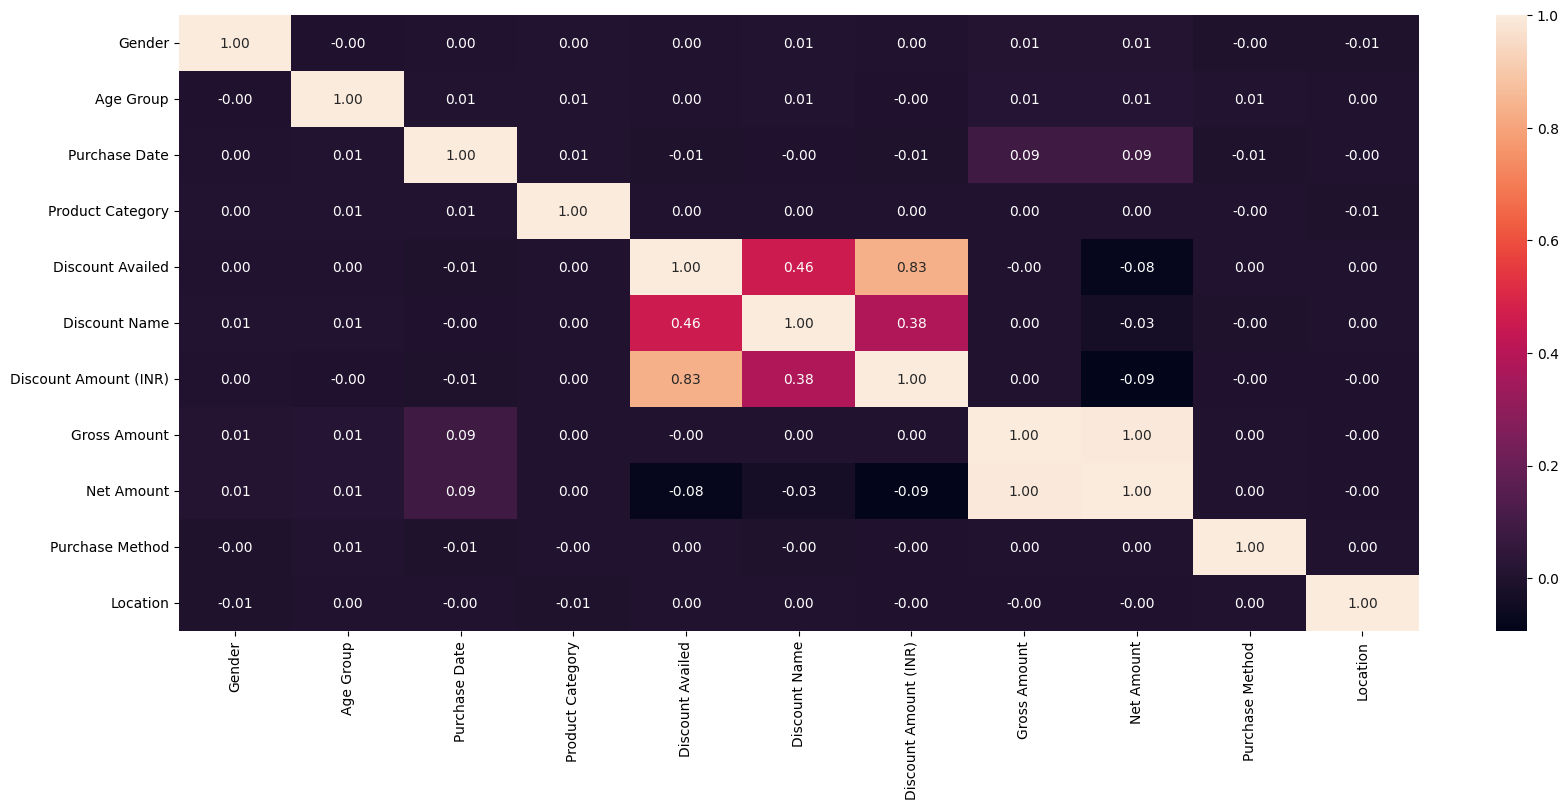

In [149]:
plt.figure(figsize=(20,8))
sns.heatmap(df.corr(),annot=True,fmt=".2f")
plt.show()